## Concrete compresive strength

### Imports

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

### Leer el dataset

In [7]:
data = pd.read_excel('/content/Concrete_Data.xls')

print(data.shape)
data.head()

(1030, 9)


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [8]:
data.columns = ["Cement", "Blast Furnace Slag", "Fly Ash", "Water", "Superplasticizer ", "Coarse Aggregate", "Fine Aggregate", "Age", "Concrete compressive"]
data.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [9]:
data.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


### Normalizar

y = m*x + b

In [10]:
def normalizar(x, ymax, ymin, xmax, xmin):

  m = (ymax - ymin) / (xmax - xmin)
  b = ymin - m*xmin
  y = m*x + b

  return y


In [11]:
data.max()

,0
Cement,540.000000
Blast Furnace Slag,359.400000
Fly Ash,200.100000
Water,247.000000
Superplasticizer,32.200000
Coarse Aggregate,1145.000000
Fine Aggregate,992.600000
Age,365.000000
Concrete compressive,82.599225


In [12]:
data2 = normalizar(data, 1, -1, data.max(), data.min())
data2.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive
0,1.000000,-1.000000,-1.0,-0.357285,-0.84472,0.389535,-0.588560,-0.851648,0.934890
1,1.000000,-1.000000,-1.0,-0.357285,-0.84472,0.476744,-0.588560,-0.851648,0.483929
2,0.052511,-0.207012,-1.0,0.696607,-1.00000,-0.238372,-1.000000,0.478022,-0.054717
3,0.052511,-0.207012,-1.0,0.696607,-1.00000,-0.238372,-1.000000,1.000000,-0.035201
4,-0.558904,-0.263216,-1.0,0.121756,-1.00000,0.031395,0.161565,0.972527,0.045612


<Figure size 1200x1000 with 0 Axes>

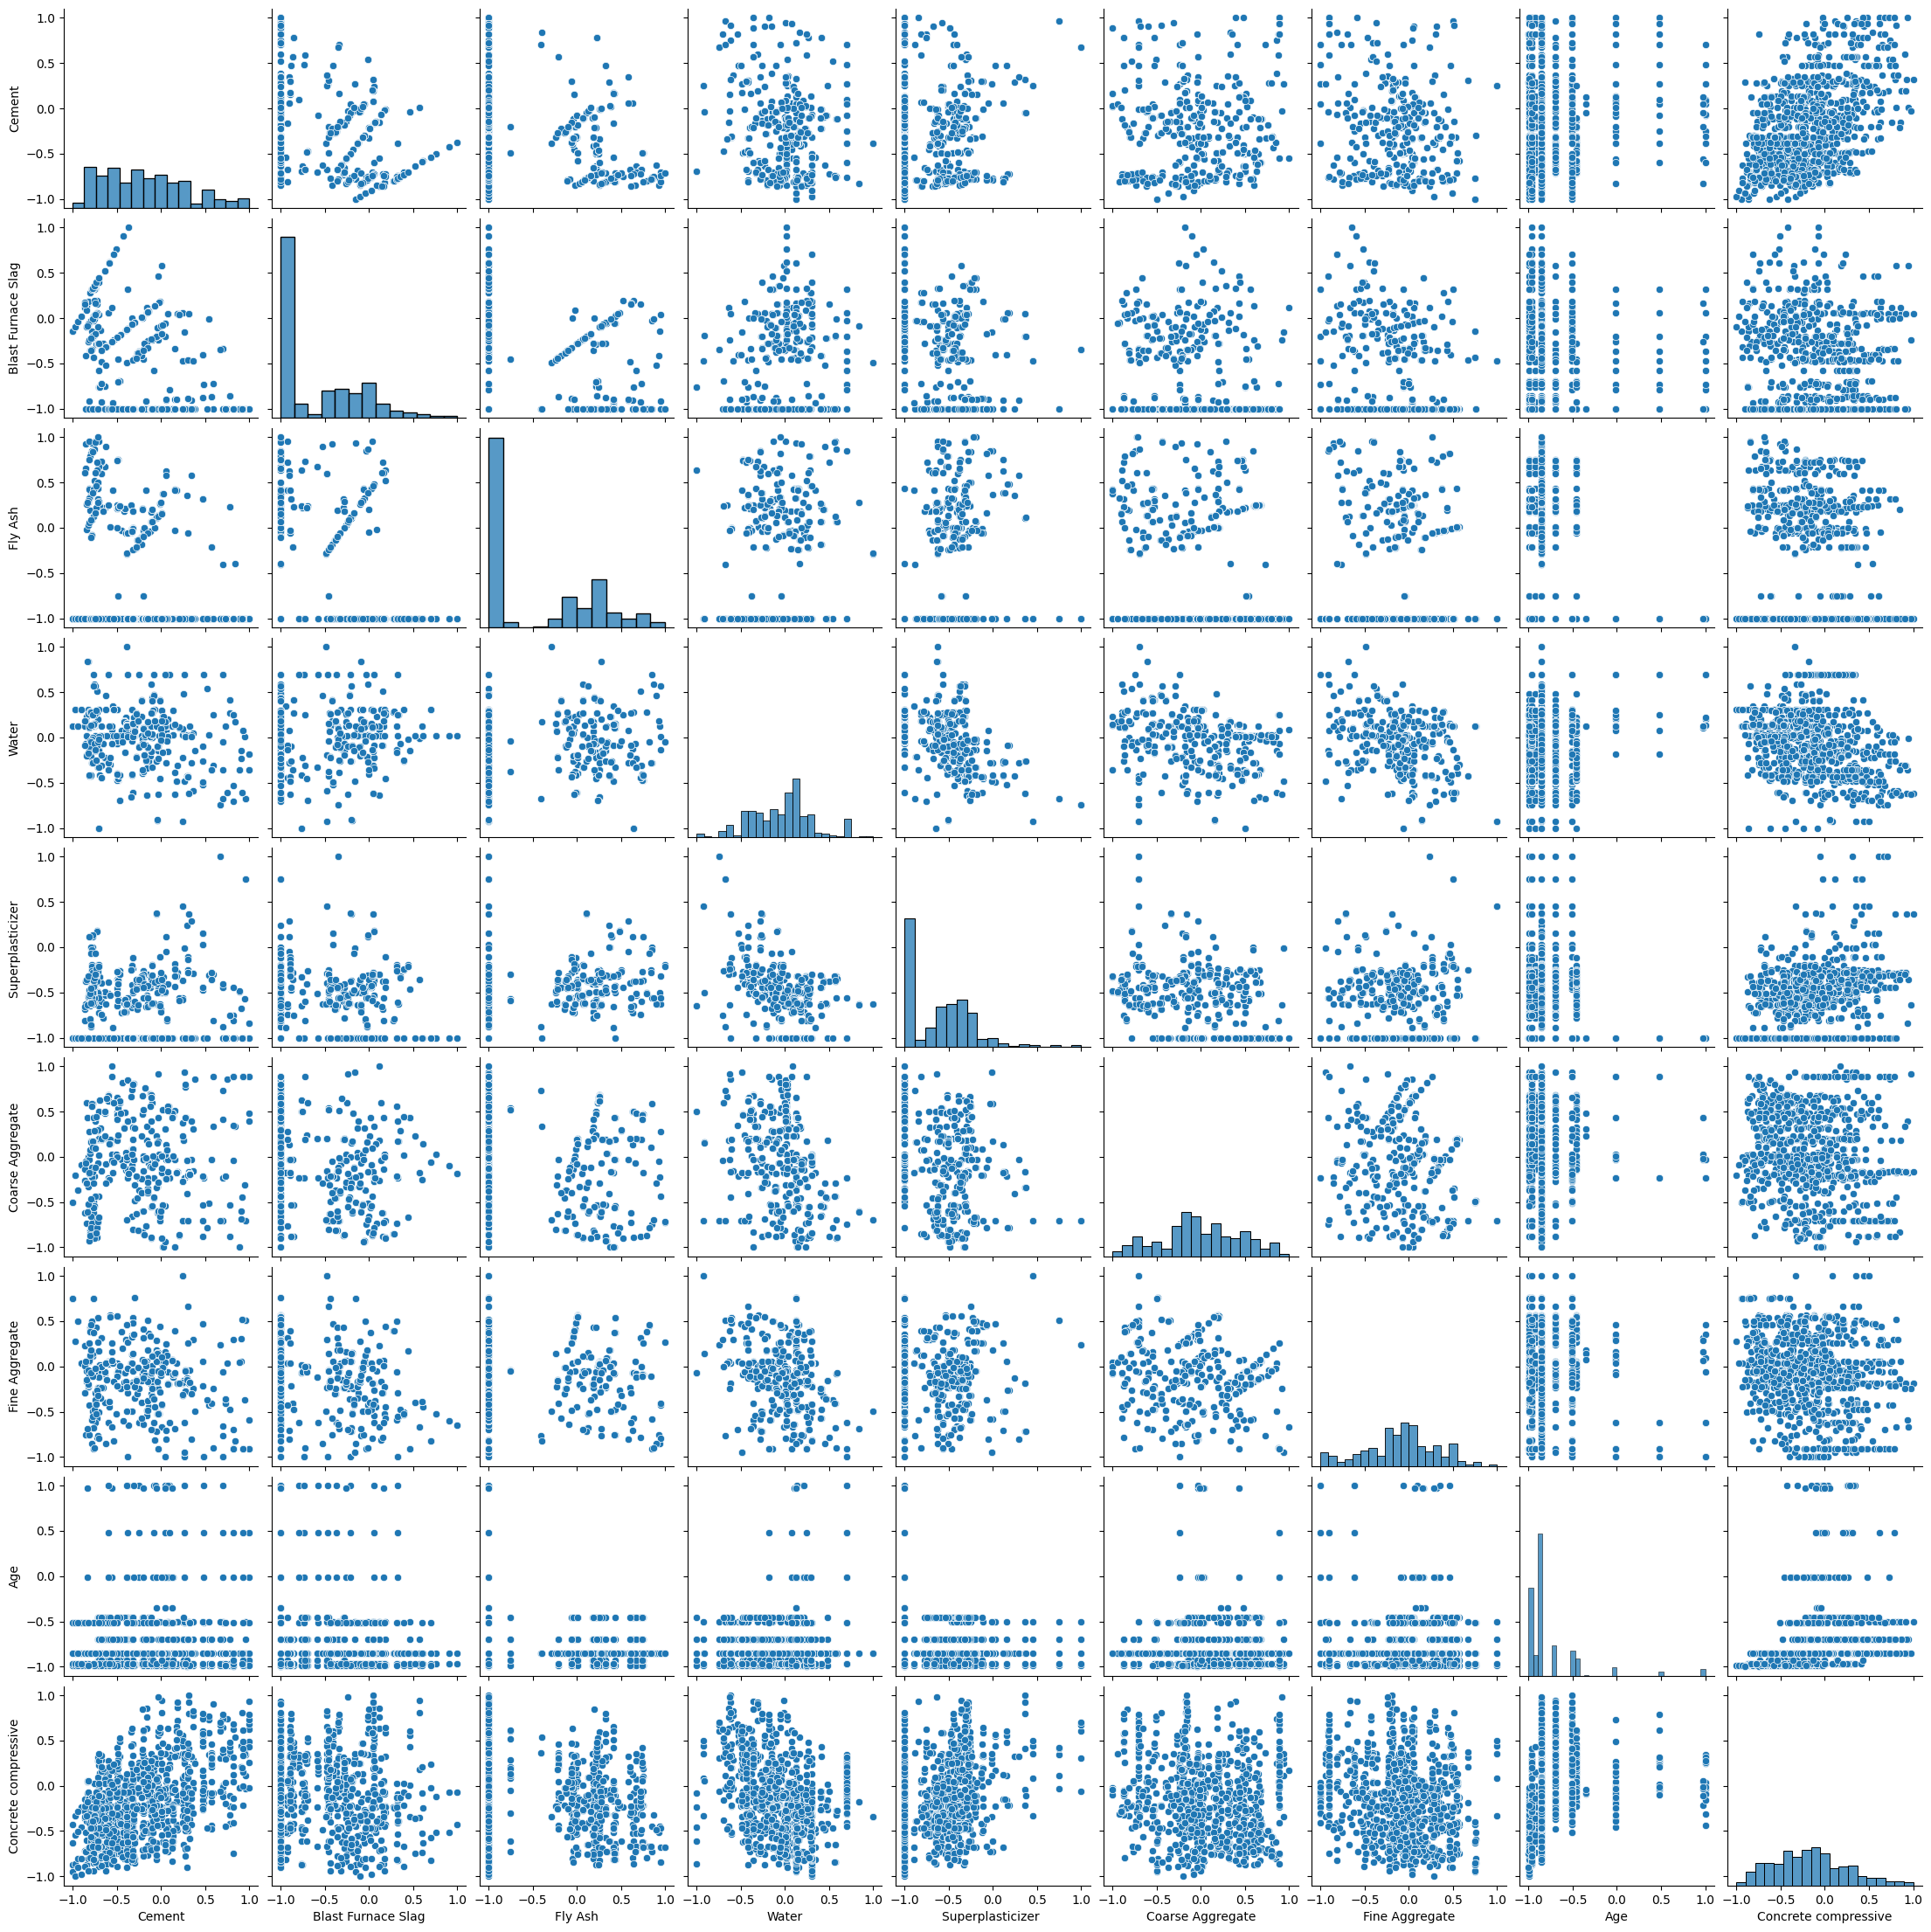

In [13]:
plt.figure(figsize=(12, 10))
sns.pairplot(data2)
plt.show()

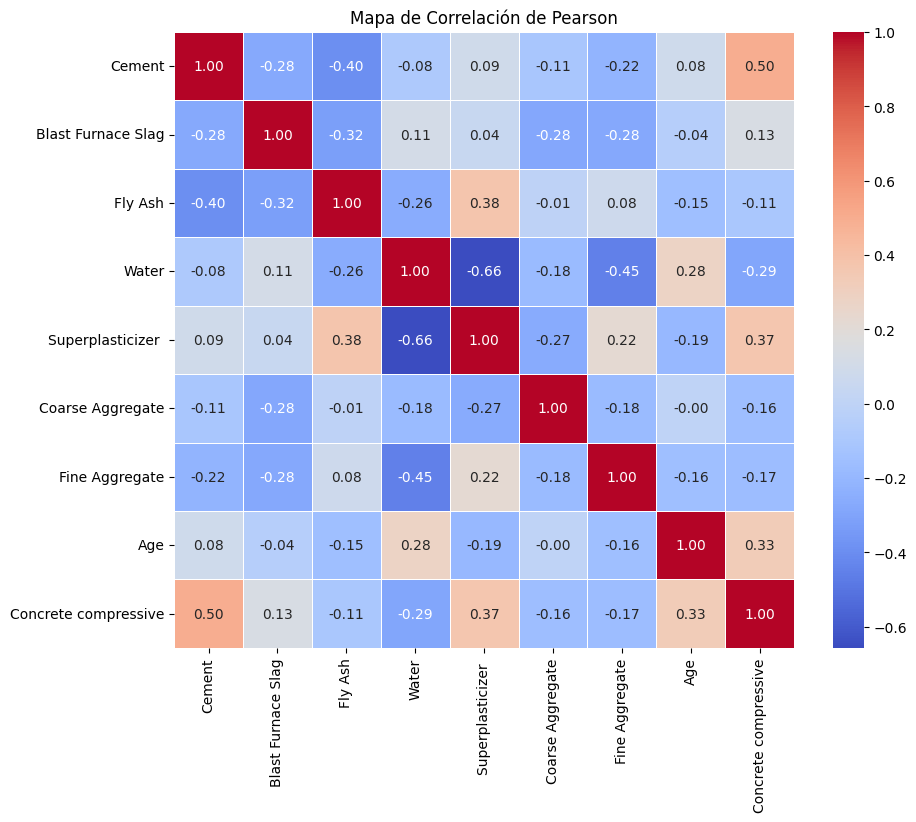

In [14]:
plt.figure(figsize=(10, 8))
correlation_matrix = data.corr(method='pearson')
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Mapa de Correlación de Pearson')
plt.show()

### Separara variables de target

In [16]:
x_train = data2.drop('Concrete compressive', axis=1)
y_train = data2['Concrete compressive']

print(x_train.shape)
print(y_train.shape)

(1030, 8)
(1030,)


### Split de mis datos

In [17]:
from sklearn.model_selection import train_test_split

X_train, x_test, Y_train, y_test = train_test_split(x_train, y_train, test_size=0.2, random_state=42)

print(X_train.shape)
print(x_test.shape)
print(Y_train.shape)
print(y_test.shape)


(824, 8)
(206, 8)
(824,)
(206,)


### Regresión lineal

In [18]:
from sklearn import linear_model

regr = linear_model.LinearRegression()
regr.fit(X_train, Y_train)

LinearRegression()

### Predict

In [19]:
result = regr.predict(x_test)

print(result.shape)
print(y_test.shape)

(206,)
(206,)


### Comparacion del Resultado del modelo vs los y_test

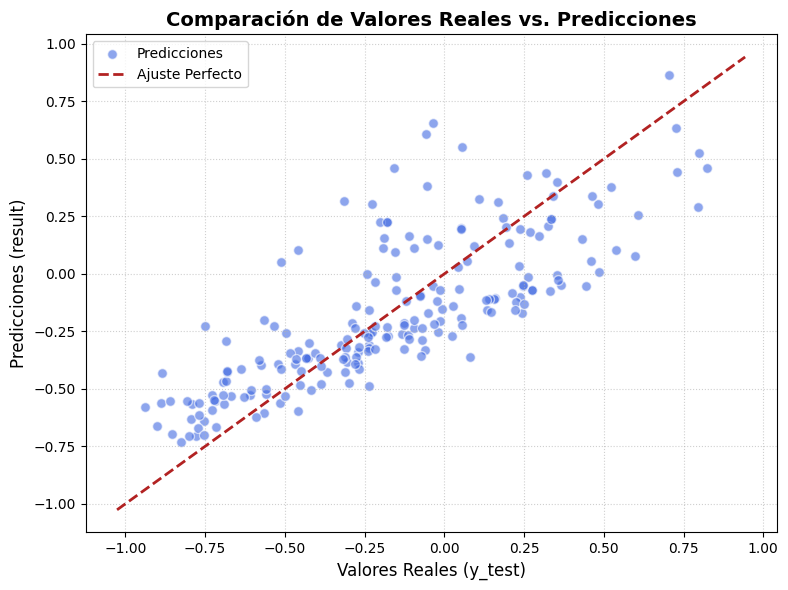

In [ ]:
plt.figure(figsize=(8, 6))
# Graficar los puntos con transparencia para ver la densidad
plt.scatter(y_test, result, color='royalblue', alpha=0.6, edgecolors='w', s=50, label='Predicciones')

# Línea diagonal de referencia (ajuste perfecto)
lims = [min(plt.xlim()[0], plt.ylim()[0]), max(plt.xlim()[1], plt.ylim()[1])]
plt.plot(lims, lims, color='firebrick', linestyle='--', linewidth=2, label='Ajuste Perfecto')

plt.xlabel('Valores Reales (y_test)', fontsize=12)
plt.ylabel('Predicciones (result)', fontsize=12)
plt.title('Comparación de Valores Reales vs. Predicciones', fontsize=14, fontweight='bold')
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [21]:
coef = regr.coef_
print(coef)

[ 0.64921887  0.48589206  0.20483934 -0.21176611  0.12385064  0.0763037
  0.11948473  0.52805722]


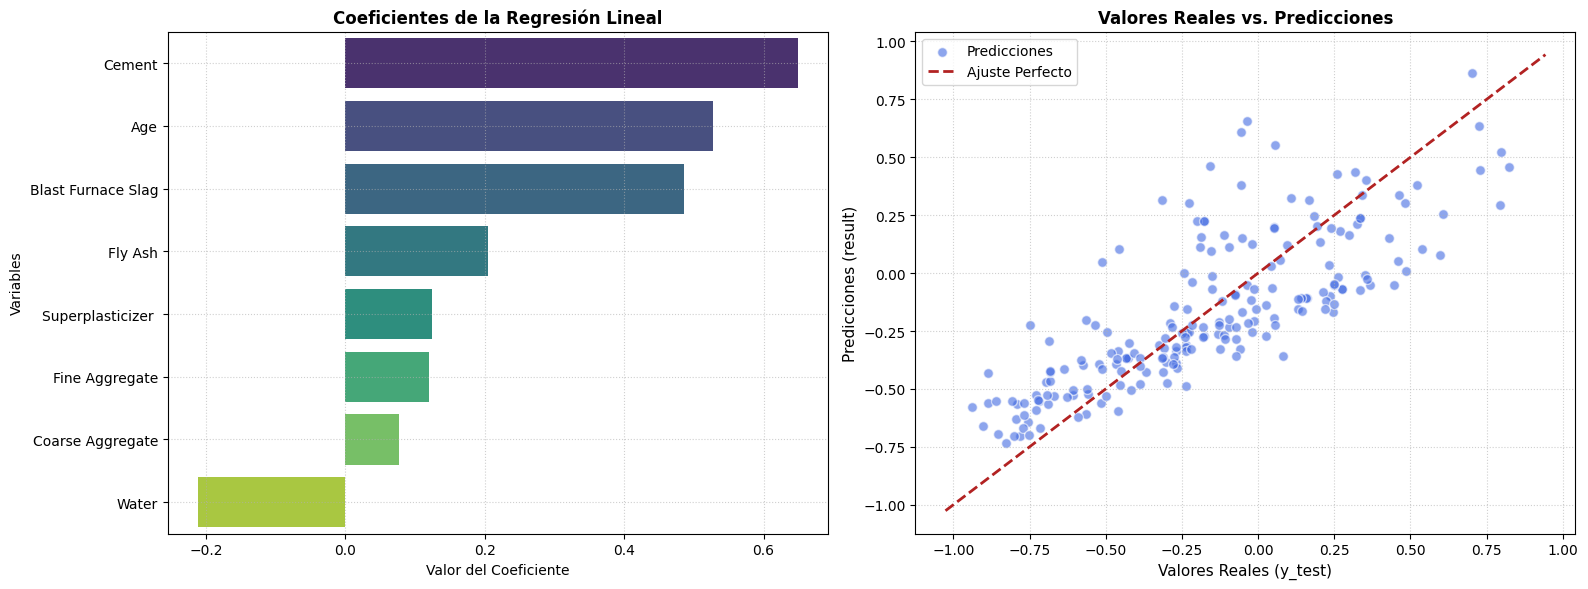

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Crear una figura con dos subgráficos uno al lado del otro
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Gráfica de Coeficientes de Regresión
coef_df = pd.DataFrame({
    'Variable': x_train.columns,
    'Coeficiente': coef
}).sort_values(by='Coeficiente', ascending=False)

sns.barplot(x='Coeficiente', y='Variable', data=coef_df, ax=axes[0], hue='Variable', palette='viridis', legend=False)
axes[0].set_title('Coeficientes de la Regresión Lineal', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Valor del Coeficiente')
axes[0].set_ylabel('Variables')
axes[0].grid(True, linestyle=':', alpha=0.6)

# 2. Gráfica de Predichos vs. Reales
axes[1].scatter(y_test, result, color='royalblue', alpha=0.6, edgecolors='w', s=50, label='Predicciones')
lims = [min(axes[1].get_xlim()[0], axes[1].get_ylim()[0]), max(axes[1].get_xlim()[1], axes[1].get_ylim()[1])]
axes[1].plot(lims, lims, color='firebrick', linestyle='--', linewidth=2, label='Ajuste Perfecto')
axes[1].set_xlabel('Valores Reales (y_test)', fontsize=11)
axes[1].set_ylabel('Predicciones (result)', fontsize=11)
axes[1].set_title('Valores Reales vs. Predicciones', fontsize=12, fontweight='bold')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### Ahora se entrena un MLP

In [23]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import tensorflow as tf


In [51]:
def model():
  model = Sequential()
  model.add(Dense(128, activation='relu', input_shape=(x_train.shape[1],)))
  model.add(Dense(64, activation='relu'))
  model.add(Dense(32, activation='relu'))
  model.add(Dense(1))

  model.summary()
  opt = tf.keras.optimizers.Adam(learning_rate=0.001)
  model.compile(loss='mse', optimizer=opt)

  return model

In [52]:
# Instanciamos el modelo guardándolo en una variable con nombre distinto a la función
mlp_model = model()

# Ahora entrenamos el modelo usando la nueva variable sin conflictos de nombres
history = mlp_model.fit(X_train, Y_train, epochs=100, batch_size=32, verbose=1, validation_data=(x_test, y_test), shuffle=True)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,521 (45.00 KB)

 Trainable params: 11,521 (45.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.2766 - val_loss: 0.1979
Epoch 2/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1892 - val_loss: 0.1463
Epoch 3/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1525 - val_loss: 0.1225
Epoch 4/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1321 - val_loss: 0.1093
Epoch 5/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1167 - val_loss: 0.0984
Epoch 6/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1046 - val_loss: 0.0902
Epoch 7/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0955 - val_loss: 0.0844
Epoch 8/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0898 - val_loss: 0.0809
Epoch 9/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0859 - val_loss: 0.0780
Epoch 10/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0826 - val_loss: 0.0757
Epoch 11/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0801 - val_loss: 0.0734
Epoch 12/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0

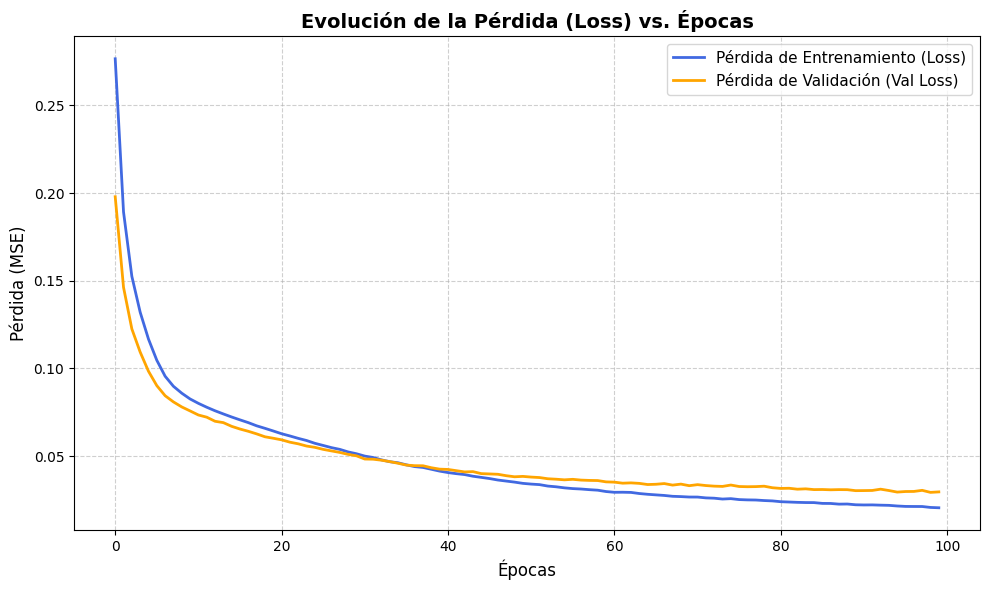

In [53]:
import matplotlib.pyplot as plt

# Graficar la pérdida (loss) vs épocas
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Pérdida de Entrenamiento (Loss)', color='royalblue', linewidth=2)
plt.plot(history.history['val_loss'], label='Pérdida de Validación (Val Loss)', color='orange', linewidth=2)

plt.title('Evolución de la Pérdida (Loss) vs. Épocas', fontsize=14, fontweight='bold')
plt.xlabel('Épocas', fontsize=12)
plt.ylabel('Pérdida (MSE)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Comparacion del Resultado del modelo vs los y_test

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


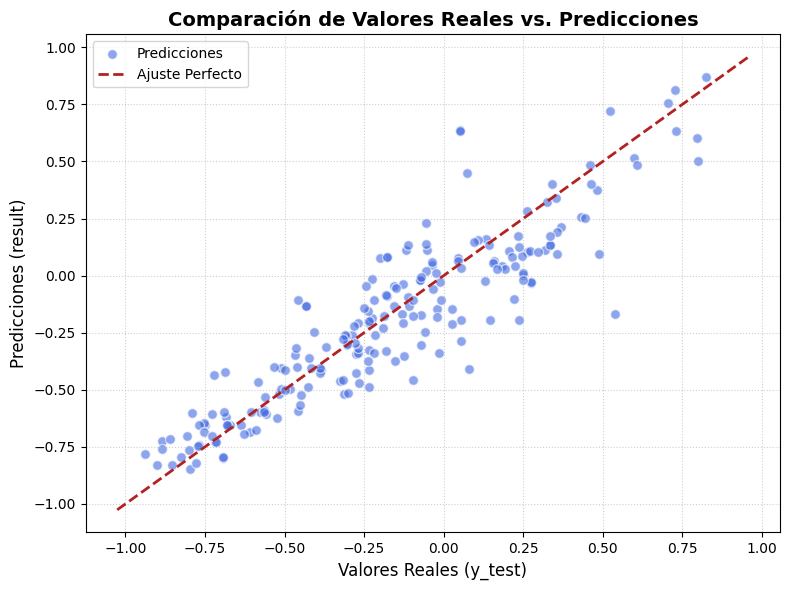

In [54]:
mlp_resultados = mlp_model.predict(x_test)



plt.figure(figsize=(8, 6))

# Graficar los puntos con transparencia para ver la densidad
plt.scatter(y_test, mlp_resultados, color='royalblue', alpha=0.6, edgecolors='w', s=50, label='Predicciones')

# Línea diagonal de referencia (ajuste perfecto)
lims = [min(plt.xlim()[0], plt.ylim()[0]), max(plt.xlim()[1], plt.ylim()[1])]
plt.plot(lims, lims, color='firebrick', linestyle='--', linewidth=2, label='Ajuste Perfecto')

plt.xlabel('Valores Reales (y_test)', fontsize=12)
plt.ylabel('Predicciones (result)', fontsize=12)
plt.title('Comparación de Valores Reales vs. Predicciones', fontsize=14, fontweight='bold')
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()